# 07 · EDA bivariado

**Fase CRISP-DM:** 2. Entendimiento de los datos

**Objetivo:** medir cómo se relacionan las variables **de a pares**, para saber qué features tienen señal y cuáles son redundantes antes de modelar.

**Dos reglas que guían todo el notebook:**

1. **Pruebas no paramétricas.** Ninguna variable es normal (notebook 06), así que se usa Spearman (numérica contra numérica), Kruskal-Wallis (numérica contra categórica) y chi² (categórica contra categórica).
2. **Se interpreta el tamaño del efecto, no el p-valor.** Con cientos de miles de filas, cualquier diferencia minúscula da p ≈ 0. El p-valor solo dice "no es exactamente cero"; el **tamaño del efecto** (ρ de Spearman, ε², V de Cramér) dice si **importa**.

| Tamaño del efecto | despreciable | pequeño | moderado | fuerte |
|---|---|---|---|---|
| ρ de Spearman, V de Cramér | < 0.1 | 0.1 a 0.3 | 0.3 a 0.5 | ≥ 0.5 |
| ε² (Kruskal-Wallis) | < 0.01 | 0.01 a 0.06 | 0.06 a 0.14 | ≥ 0.14 |

**Entradas:** tablas del contrato (sin verdad oculta). **Salidas:** figuras `reports/figures/07_*.png` y la lista de features con señal para el notebook 10.

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración y tablas por unidad

Cada pregunta se responde en su unidad: **mesa** (ticket, hora), **comensal** (frecuencia, gustos), **platillo** (precio, popularidad).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from puzzle_recsys.config import load_paths, load_simulation
from puzzle_recsys.eda.bivariate import cramers_v, kruskal_effect, spearman_pairs
from puzzle_recsys.eda.frames import diner_frame, item_frame, session_frame
from puzzle_recsys.eda.plots import plot_by_group
from puzzle_recsys.features.calendar import MEAL_PERIODS
from puzzle_recsys.repository.parquet_repo import ParquetRepository, run_id_for

paths, sim = load_paths(), load_simulation()
repo = ParquetRepository(paths.synthetic / run_id_for(sim.run_name, sim.seed))
t = {n: repo.read_table(n) for n in ["restaurants", "menu_items", "dining_sessions", "guests",
                                     "order_items", "dish_ratings", "diner_profiles"]}
figs = paths.figures
figs.mkdir(parents=True, exist_ok=True)

mesas = session_frame(t["dining_sessions"], t["order_items"], t["restaurants"], t["menu_items"], sim.calendar["timezone"])
platillos = item_frame(t["menu_items"], t["order_items"], t["dish_ratings"], t["restaurants"])
comensales = diner_frame(t["guests"], mesas, t["order_items"], t["menu_items"], t["diner_profiles"])
pd.Series({"mesas": len(mesas), "platillos": len(platillos), "comensales registrados": len(comensales)}, name="filas").to_frame().T

,mesas,platillos,comensales registrados
filas,514510,36115,20221


## 1. Numérica contra numérica (Spearman)

Spearman trabaja con **rangos**: detecta relaciones monótonas aunque no sean lineales y no se deja arrastrar por las colas largas.

In [2]:
pairs = pd.concat([
    spearman_pairs(mesas[["pax", "ticket", "ticket_por_persona", "nivel_precio", "hora"]]).assign(unidad="mesa"),
    spearman_pairs(comensales[["visitas", "restaurantes_distintos", "ticket_por_persona_mediano",
                               "share_cocina_top", "picante_pedido", "picante_declarado"]]).assign(unidad="comensal"),
    spearman_pairs(platillos[["precio", "precio_relativo", "veces_pedido", "spice_level",
                              "estrellas_medias"]]).assign(unidad="platillo"),
])
pairs = pairs.assign(abs_rho=pairs["rho"].abs()).sort_values(["unidad", "abs_rho"], ascending=[True, False])
pairs[["unidad", "a", "b", "rho", "n", "efecto"]].round(3).reset_index(drop=True)

,unidad,a,b,rho,n,efecto
0,comensal,visitas,restaurantes_distintos,0.841,20221,fuerte
1,comensal,restaurantes_distintos,ticket_por_persona_mediano,0.412,20221,moderado
2,comensal,picante_pedido,picante_declarado,0.382,12070,moderado
3,comensal,visitas,ticket_por_persona_mediano,0.378,20221,moderado
4,comensal,share_cocina_top,picante_pedido,0.205,20221,pequeño
5,comensal,ticket_por_persona_mediano,share_cocina_top,0.193,20221,pequeño
6,comensal,visitas,share_cocina_top,0.168,20221,pequeño
7,comensal,ticket_por_persona_mediano,picante_pedido,0.072,20221,despreciable
8,comensal,visitas,picante_pedido,0.053,20221,despreciable
9,comensal,restaurantes_distintos,picante_pedido,0.023,20221,despreciable


## 2. Numérica contra categórica (Kruskal-Wallis)

¿La distribución de una variable numérica cambia entre grupos? ε² es la proporción de la variación (en rangos) que explica el grupo.

In [3]:
tests = [
    ("mesa", mesas, "ticket_por_persona", "franja"),
    ("mesa", mesas, "ticket_por_persona", "dia"),
    ("mesa", mesas, "ticket_por_persona", "cocina"),
    ("mesa", mesas, "ticket_por_persona", "alcaldia"),
    ("mesa", mesas, "ticket_por_persona", "personal"),
    ("mesa", mesas, "pax", "franja"),
    ("mesa", mesas, "pax", "dia"),
    ("platillo", platillos, "precio", "course"),
    ("platillo", platillos, "precio", "cocina"),
    ("platillo", platillos, "veces_pedido", "course"),
    ("platillo", platillos, "veces_pedido", "is_shareable"),
    ("platillo", platillos, "estrellas_medias", "course"),
    ("comensal", comensales, "visitas", "onboarding_completo"),
]
kw = pd.DataFrame([{"unidad": u, "variable": v, "grupo": g, **kruskal_effect(df, v, g)} for u, df, v, g in tests])
kw.sort_values("epsilon2", ascending=False)[["unidad", "variable", "grupo", "grupos", "n", "epsilon2", "p", "efecto"]].round(4).reset_index(drop=True)

,unidad,variable,grupo,grupos,n,epsilon2,p,efecto
0,platillo,precio,course,5,36115,0.3840,0.0000,fuerte
1,mesa,ticket_por_persona,cocina,20,514510,0.1987,0.0000,fuerte
2,platillo,estrellas_medias,course,5,29585,0.1576,0.0000,fuerte
3,platillo,precio,cocina,20,36115,0.0651,0.0000,moderado
4,mesa,ticket_por_persona,alcaldia,16,514510,0.0623,0.0000,moderado
5,mesa,ticket_por_persona,franja,3,514510,0.0500,0.0000,pequeño
6,platillo,veces_pedido,course,5,36115,0.0225,0.0000,pequeño
7,mesa,ticket_por_persona,personal,6,514510,0.0160,0.0000,pequeño
8,platillo,veces_pedido,is_shareable,2,36115,0.0059,0.0000,despreciable
9,mesa,pax,dia,7,514510,0.0053,0.0000,despreciable


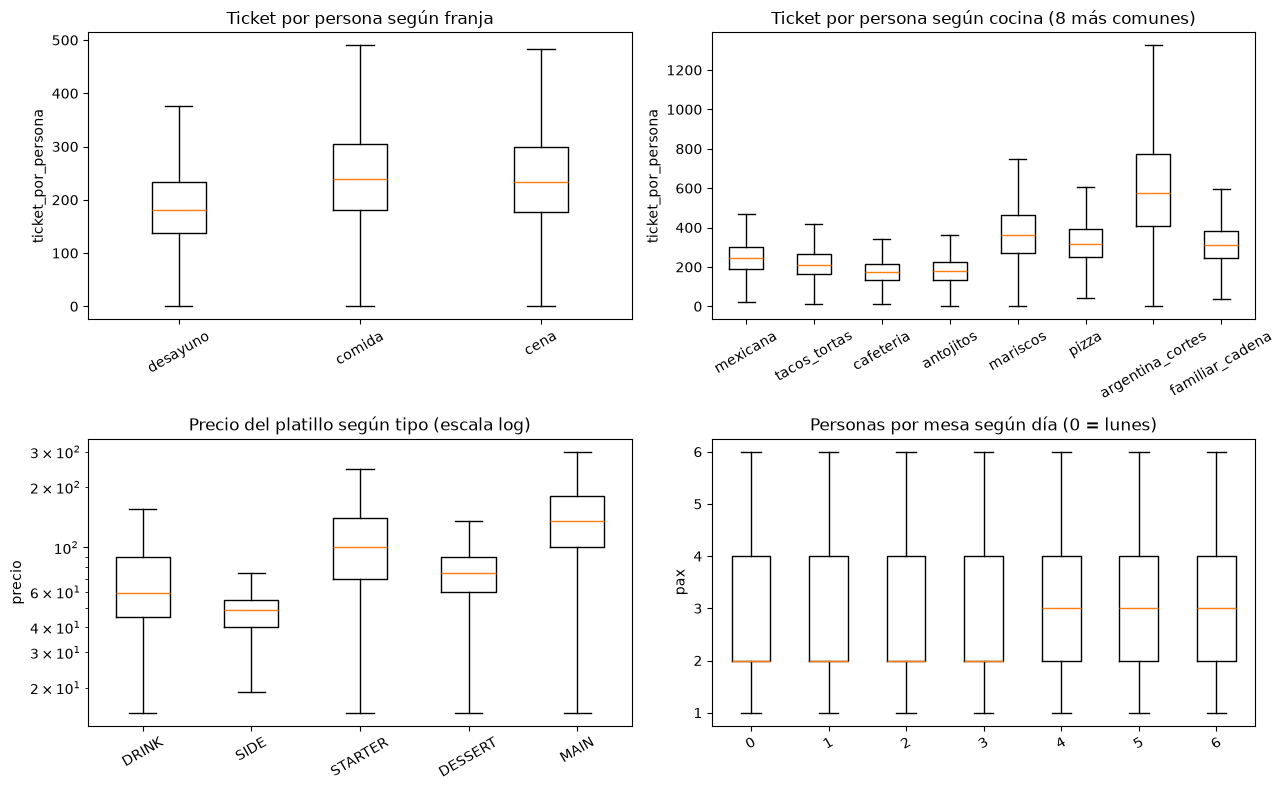

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_by_group(mesas, "ticket_por_persona", "franja", order=list(MEAL_PERIODS), title="Ticket por persona según franja", ax=axes[0, 0])
top_cocinas = mesas["cocina"].value_counts().index[:8].tolist()
plot_by_group(mesas, "ticket_por_persona", "cocina", order=top_cocinas, title="Ticket por persona según cocina (8 más comunes)", ax=axes[0, 1])
plot_by_group(platillos, "precio", "course", order=["DRINK", "SIDE", "STARTER", "DESSERT", "MAIN"], log=True, title="Precio del platillo según tipo (escala log)", ax=axes[1, 0])
plot_by_group(mesas, "pax", "dia", order=list(range(7)), title="Personas por mesa según día (0 = lunes)", ax=axes[1, 1])
fig.tight_layout()
fig.savefig(figs / "07_por_grupo.png", dpi=150)

## 3. Categórica contra categórica (chi² y V de Cramér)

La V de Cramér va de 0 (independientes) a 1 (una determina la otra). Se usa la versión **corregida por sesgo**: sin corrección, tablas con muchas categorías aparentan asociación aunque no la haya.

In [5]:
lines = t["order_items"].merge(t["menu_items"][["menu_item_id", "course"]], on="menu_item_id")
lines = lines.merge(mesas[["session_id", "franja", "fin_de_semana"]], on="session_id")
onboarded = comensales.dropna(subset=["cocina_favorita_declarada"])
cat_tests = [
    ("línea", "tipo de plato × franja", lines["course"], lines["franja"]),
    ("línea", "compartida × tipo de plato", lines["is_shared"], lines["course"]),
    ("mesa", "cocina × franja", mesas["cocina"], mesas["franja"]),
    ("mesa", "cocina × fin de semana", mesas["cocina"], mesas["fin_de_semana"]),
    ("restaurante", "cocina × alcaldía", t["restaurants"]["cuisine_pred"], t["restaurants"]["alcaldia"]),
    ("comensal", "cocina favorita declarada × más visitada", onboarded["cocina_favorita_declarada"], onboarded["cocina_mas_visitada"]),
]
cv = pd.DataFrame([{"unidad": u, "par": name, **cramers_v(x, y)} for u, name, x, y in cat_tests])
cv.sort_values("V", ascending=False)[["unidad", "par", "n", "V", "p", "efecto"]].round(4).reset_index(drop=True)

,unidad,par,n,V,p,efecto
0,línea,compartida × tipo de plato,3409935,0.2273,0.000,pequeño
1,comensal,cocina favorita declarada × más visitada,12070,0.2091,0.000,pequeño
2,mesa,cocina × franja,514510,0.1849,0.000,pequeño
3,línea,tipo de plato × franja,3409935,0.0682,0.000,despreciable
4,restaurante,cocina × alcaldía,1500,0.0395,0.076,despreciable
5,mesa,cocina × fin de semana,514510,0.0106,0.000,despreciable


Detalle de las dos asociaciones que importan para el producto: qué se pide en cada franja y qué se comparte.

In [6]:
display(pd.crosstab(lines["franja"], lines["course"], normalize="index").mul(100).round(1).rename_axis(index="franja (% de sus líneas)"))
pd.crosstab(lines["course"], lines["is_shared"], normalize="index").mul(100).round(1).rename(columns={False: "individual", True: "compartida"}).rename_axis(index="tipo de plato (%)")

course,DESSERT,DRINK,MAIN,SIDE,STARTER
franja (% de sus líneas),,,,,
desayuno,7.9,40.6,40.5,1.9,9.1
comida,9.7,30.1,39.6,3.0,17.7
cena,10.4,33.2,38.3,3.1,15.0


is_shared,individual,compartida
tipo de plato (%),,
DESSERT,91.0,9.0
DRINK,100.0,0.0
MAIN,98.4,1.6
SIDE,87.1,12.9
STARTER,90.4,9.6


Y qué cocina gana en cada franja (participación de las mesas de cada franja, cocinas más comunes):

In [7]:
top = mesas["cocina"].value_counts().index[:8]
pd.crosstab(mesas["franja"], mesas["cocina"], normalize="index")[top].mul(100).round(1).rename_axis(index="franja (% de sus mesas)")

cocina,mexicana,tacos_tortas,cafeteria,antojitos,mariscos,pizza,argentina_cortes,familiar_cadena
franja (% de sus mesas),,,,,,,,
desayuno,47.9,13.4,30.0,4.7,1.3,0.5,0.2,1.6
comida,52.9,17.4,13.6,3.9,5.4,2.4,1.3,1.1
cena,42.3,28.2,10.8,6.2,3.1,4.3,1.6,1.0


## 4. Hallazgos para el diseño de features

**¿El onboarding sirve para el arranque en frío?** Si lo que la gente **declara** se parece a lo que **hace**, se puede usar para recomendar desde la primera visita.

In [8]:
match = (onboarded["cocina_favorita_declarada"] == onboarded["cocina_mas_visitada"]).mean()
spice = comensales.dropna(subset=["picante_declarado", "picante_pedido"])
pd.Series({
    "% cuya cocina favorita declarada = la más visitada": round(match * 100, 1),
    "ρ picante declarado vs. pedido": round(spice[["picante_declarado", "picante_pedido"]].corr("spearman").iloc[0, 1], 3),
    "comensales con onboarding": len(onboarded),
}).to_frame("valor").T

,% cuya cocina favorita declarada = la más visitada,ρ picante declarado vs. pedido,comensales con onboarding
valor,43.0,0.382,12070.0


## Conclusiones

### 1. Lo que este EDA destapó: la hora no influía en nada

La primera corrida mostró que **la franja y el día no cambiaban nada**: en el desayuno se pedían los mismos postres y platos fuertes que en la cena (V = 0.001) y una cafetería recibía la misma proporción de mesas a las 9 que a las 21 (V = 0.000). El simulador solo usaba la hora para repartir visitas. Como el modelo va a arrancar la app, se agregó el **efecto del contexto** (supuesto S16; notebook 03, corrección 7) y se volvió a ejecutar toda la cadena. Ahora:

| Efecto | Desayuno | Comida | Cena |
|---|---|---|---|
| Cafetería (% de las mesas) | 30.0 | 13.6 | 10.8 |
| Tacos y tortas (% de las mesas) | 13.4 | 17.4 | 28.2 |
| Bebida (% de las líneas) | 40.6 | 30.1 | 33.2 |
| Entrada (% de las líneas) | 9.1 | 17.7 | 15.0 |
| Ticket mediano por persona | $180 | $238 | $233 |

- Cocina × franja: V = **0.18** (antes 0.000). Tipo de plato × franja: V = **0.07** (antes 0.001). Ticket por persona según franja: ε² = **0.05** (antes 0.000).
- Fuera de las tablas del notebook (verificado aparte): el alcohol pasa de 10 % de las bebidas en el desayuno a 52 % en la cena, y los platos fuertes "de desayuno" (chilaquiles, huevos, molletes) de 45 % a 15 % de los fuertes.
- El fin de semana las mesas son algo más grandes (2.97 contra 2.77 personas); el efecto es real pero chico (ε² = 0.005).

### 2. Las señales más fuertes

- **Tipo de plato → precio** (ε² = 0.38) y **cocina → ticket por persona** (ε² = 0.20): el precio depende sobre todo de qué y dónde.
- **Nivel de precio del restaurante ↔ ticket por persona** (ρ = 0.60): el lugar define cuánto se gasta.
- **Compartir depende del tipo de plato** (V = 0.23): las bebidas nunca se comparten; las guarniciones (13 %), entradas (10 %) y postres (9 %), sí; el plato fuerte casi nunca (1.6 %). La lista "para la mesa" debe centrarse en entradas, guarniciones y postres.

### 3. Lo que casi no importa (y por qué está bien)

- **Precio relativo ↔ popularidad** (ρ = 0.05): dentro de un menú, el precio casi no explica qué se pide; pesan más los gustos. Es una señal débil, documentada en la ficha del modelo.
- **Cocina × alcaldía** (V = 0.04, p = 0.08): con los datos reales del DENUE las cocinas no se concentran por alcaldía.
- **Onboarding completo ↔ visitas** (ε² = 0.000): coherente con el faltante MCAR del notebook 05.

### 4. Redundancias (para no meter la misma información dos veces)

- **Visitas ↔ restaurantes distintos** (ρ = 0.84): casi la misma información; en el modelo conviene usar una de las dos o su cociente (variedad).
- **Personas ↔ ticket** (ρ = 0.81): esperable; por eso se usa el ticket **por persona**.

### 5. El onboarding sirve para el arranque en frío

El 43 % de quienes lo completaron visita sobre todo la cocina que declaró como favorita (V = 0.21) y el picante declarado se parece al pedido (ρ = 0.38). Es una señal **moderada**: sirve para la primera visita, pero el historial la debe reemplazar en cuanto exista.

### 6. Estrellas: con cuidado

Los platillos más pedidos tienen mejores estrellas (ρ = 0.28) y los más picantes y más caros, peores (ρ = -0.27 y -0.23). Pero las estrellas son MNAR (notebook 05): solo se usan como señal auxiliar.

**Features con señal que pasan al notebook 10:** franja, fin de semana, cocina, nivel de precio del restaurante, tipo de plato, precio relativo, popularidad del platillo, cocina favorita y picante declarados.

**Pasa al notebook 08:** estructura multivariada y segmentos de comensales.
